# Module 5: Social Media Engagement Analytics
## Task 1: Data Import and Setup

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [91]:
# Dataset URL
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"

# Load Dataset
df = pd.read_csv(url)

In [92]:
# Display first 5 rows
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [93]:
# Convert 'likes' and 'comments' columns into NumPy arrays
likes_array = np.array(df['likes'])
comments_array = np.array(df['comments'])

# Perform NumPy operations (using np.nan* to handle missing values safely)
print("--- Task 1: NumPy Array Operations ---")
print(f"Total Likes (np.nansum): {np.nansum(likes_array):,.0f}")
print(f"Average Likes (np.nanmean): {np.nanmean(likes_array):.2f}")
print(f"Max Comments (np.nanmax): {np.nanmax(comments_array):,.0f}")
print(f"Std Dev of Likes (np.nanstd): {np.nanstd(likes_array):.2f}")

--- Task 1: NumPy Array Operations ---
Total Likes (np.nansum): 49,019,162
Average Likes (np.nanmean): 10107.04
Max Comments (np.nanmax): 2,999
Std Dev of Likes (np.nanstd): 5789.22


# Task 2: Data Cleaning and Preprocessing
## Step 2.1: Identify Missing Values

In [94]:
# Check initial missing values per column
print("--- Missing Values Count per Column ---")
print(df.isnull().sum())

--- Missing Values Count per Column ---
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


### Step 2.2: Handle Missing Values and Duplicates

In [95]:
# 1. Drop duplicate rows if any
df = df.drop_duplicates()

# 2. Fill missing numerical columns with median
num_cols = ['age', 'likes', 'comments', 'shares']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# 3. Fill missing categorical columns with mode
cat_cols = ['gender', 'sentiment']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify missing values after cleaning
print("--- Missing Values After Handling ---")
print(df.isnull().sum())

--- Missing Values After Handling ---
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


### Step 2.3: Convert Date Column to Datetime

In [96]:
# Convert 'posted_at' column to datetime format safely
df['posted_at'] = pd.to_datetime(df['posted_at'], format='mixed', dayfirst=True)

# Verify the data type
print(f"Data type of 'posted_at': {df['posted_at'].dtype}")
df[['posted_at']].head()

Data type of 'posted_at': datetime64[ns]


,posted_at
0,2022-12-17
1,2023-06-02
2,2023-05-07
3,2023-02-12
4,2023-05-23


### Step 2.4: Standardize Text and Categorical Labels

In [97]:
# Standardize text columns (strip spaces and convert to title case)
text_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']

for col in text_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

# Check unique values in standardized columns
print("Unique values in 'gender':", df['gender'].unique())
print("Unique values in 'sentiment':", df['sentiment'].unique())

Unique values in 'gender': ['Female' 'Male' 'Other']
Unique values in 'sentiment': ['Negative' 'Positive' 'Neutral']


### Step 2.5: Correct Unrealistic Values in Engagement Metrics

In [98]:
# Check for negative or invalid values in engagement metrics
print("Negative likes count:", (df['likes'] < 0).sum())
print("Negative comments count:", (df['comments'] < 0).sum())
print("Negative shares count:", (df['shares'] < 0).sum())

# Ensure non-negative bounds
df['likes'] = df['likes'].clip(lower=0)
df['comments'] = df['comments'].clip(lower=0)
df['shares'] = df['shares'].clip(lower=0)

Negative likes count: 0
Negative comments count: 0
Negative shares count: 0


### Step 2.6: Feature Cleaning (Hashtag Count & Sentiment Labels)

In [99]:
# 1. Extract hashtag count from 'hashtags' column
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split()) if pd.notnull(x) and str(x).strip() != '' else 0
)

# 2. Clean and standardize sentiment labels
df['sentiment'] = df['sentiment'].astype(str).str.strip().str.capitalize()

# Display output sample
df[['hashtags', 'hashtag_count', 'sentiment']].head()

,hashtags,hashtag_count,sentiment
0,#foodie #travel #love,3,Negative
1,#fitness,1,Negative
2,#foodie,1,Positive
3,#music #foodie #fun,3,Negative
4,#travel,1,Negative


# Task 3: Data Exploration using Pandas
## Step 3.1: View Dataset Structure

In [100]:
# Task 3.1: Explore Dataset Structure

# 1. View first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# 2. View last 5 rows
print("\n--- Last 5 Rows ---")
display(df.tail())

# 3. Shape of dataset (rows, columns)
print("\nDataset Shape (rows, columns):", df.shape)

# 4. List of all column names
print("\nColumn Names:")
print(df.columns.tolist())

--- First 5 Rows ---


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,Image,Fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,Reel,Food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32.0,Female,Uk,109864,Text,Food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,Text,Fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,Uk,449706,Image,Fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1



--- Last 5 Rows ---


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,Video,Education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,Uae,677076,Reel,Education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,Usa,273595,Text,Travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,Video,Fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,Text,Travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3



Dataset Shape (rows, columns): (5000, 20)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


## Step 3.2: Check Data Types and Info

In [101]:
# Check data types and dataset summary information
print("--- Dataset Information ---")
df.info()

print("\n--- Column Data Types ---")
print(df.dtypes)

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 

## Step 3.3: Generate Summary Statistics

In [102]:
# Display summary statistics for numerical fields
print("--- Summary Statistics (Numerical Features) ---")
display(df.describe().T)

--- Summary Statistics (Numerical Features) ---


,count,mean,min,25%,50%,75%,max,std
user_id,5000.0,54561.8908,10055.0,32309.5,54374.5,77180.5,99963.0,26090.370121
age,5000.0,38.4404,13.0,26.0,38.0,51.0,64.0,14.687151
post_id,5000.0,548042.909,100068.0,322543.5,548077.5,771574.5,999455.0,260646.957267
likes,5000.0,10106.9974,10.0,5235.0,10105.5,14959.0,19998.0,5702.293017
comments,5000.0,1502.0398,0.0,792.0,1497.0,2235.25,2999.0,856.393312
shares,5000.0,1002.9106,0.0,511.0,1012.0,1483.0,1999.0,570.8552
watch_time_sec,5000.0,4014.5032,0.0,2017.75,4034.5,6020.25,7998.0,2308.096459
impression_count,5000.0,50013.7328,105.0,24988.25,49934.5,74662.25,99995.0,28844.939104
posted_at,5000,2022-12-28 13:21:30.240000,2022-01-01 00:00:00,2022-07-03 18:00:00,2022-12-27 00:00:00,2023-06-28 00:00:00,2023-12-31 00:00:00,NaN
follower_count,5000.0,393698.2248,87.0,194480.0,388982.0,589744.25,799533.0,230927.884535


## Step 3.4: Categorical Distributions

In [103]:
# Categorical columns to analyze
cat_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']

print("--- Categorical Distributions ---")
for col in cat_cols:
    print(f"\n=== Column: {col} ===")
    print(f"Unique Count (nunique): {df[col].nunique()}")
    print(f"Unique Values: {df[col].unique()}")
    print("\nValue Counts:")
    print(df[col].value_counts())
    print("-" * 40)

--- Categorical Distributions ---

=== Column: gender ===
Unique Count (nunique): 3
Unique Values: ['Female' 'Male' 'Other']

Value Counts:
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
----------------------------------------

=== Column: country ===
Unique Count (nunique): 10
Unique Values: ['Brazil' 'Uk' 'France' 'Canada' 'Japan' 'Australia' 'India' 'Uae'
 'Germany' 'Usa']

Value Counts:
country
India        535
Canada       513
Brazil       504
Uae          503
Usa          501
France       496
Uk           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
----------------------------------------

=== Column: post_type ===
Unique Count (nunique): 4
Unique Values: ['Image' 'Reel' 'Text' 'Video']

Value Counts:
post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64
----------------------------------------

=== Column: post_category ===
Unique Count (nunique): 8
Unique Values: ['Fitness

## Step 3.5: Correlation Matrix for Numeric Fields

In [104]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Calculate correlation matrix
corr_matrix = df[numeric_cols].corr()

print("--- Correlation Matrix ---")
display(corr_matrix)

--- Correlation Matrix ---


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


## Step 3.6: Groupby Summaries

In [105]:
# 1. Average Likes and Engagement Rate by Post Type
print("--- Average Likes and Engagement Rate by Post Type ---")
display(df.groupby('post_type')[['likes', 'engagement_rate']].mean().reset_index())

# 2. Total Impressions and Shares by Country
print("\n--- Total Impressions and Shares by Country ---")
display(df.groupby('country')[['impression_count', 'shares']].sum().reset_index())

--- Average Likes and Engagement Rate by Post Type ---


,post_type,likes,engagement_rate
0,Image,10104.865277,0.895646
1,Reel,10037.802416,0.783047
2,Text,10100.148193,1.064549
3,Video,10188.600000,1.122365



--- Total Impressions and Shares by Country ---


,country,impression_count,shares
0,Australia,23834767,507639.0
1,Brazil,24793360,508465.0
2,Canada,24984716,511074.0
3,France,25656926,521699.0
4,Germany,23816649,476956.0
5,India,28067377,553894.0
6,Japan,23418816,452814.0
7,Uae,24610992,497505.0
8,Uk,25201861,485941.0
9,Usa,25683200,498566.0


In [106]:
# Task 3: Data Exploration
print("--- DATASET INFO ---")
df.info()

print("\n--- DESCRIPTIVE STATISTICS ---")
display(df.describe())

print("\n--- POST TYPE DISTRIBUTION ---")
print(df['post_type'].value_counts())

print("\n--- CORRELATION MATRIX ---")
numeric_df = df.select_dtypes(include=['float64', 'int64'])
display(numeric_df.corr())

--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853



--- POST TYPE DISTRIBUTION ---
post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64

--- CORRELATION MATRIX ---


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


# Task 4: Data Wrangling
## Step 4.1: Combining DataFrames (Concat/Merge)

In [107]:
# Split dataset into two subsets to demonstrate concatenating
df_part1 = df.iloc[:2500].copy()
df_part2 = df.iloc[2500:].copy()

# Combine DataFrames back using pd.concat
df_recombined = pd.concat([df_part1, df_part2], axis=0)

print("Recombined DataFrame Shape:", df_recombined.shape)

Recombined DataFrame Shape: (5000, 20)


## Step 4.2: Feature Engineering

In [108]:
# 1. Create engagement_score: sum of likes, comments, and shares
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

# 2. Log-transform metrics using np.log1p (to handle 0 values safely)
df['log_likes'] = np.log1p(df['likes'])
df['log_impressions'] = np.log1p(df['impression_count'])

# Display first 5 rows of newly created features
df[['likes', 'comments', 'shares', 'engagement_score', 'log_likes', 'log_impressions', 'hashtag_count']].head()

,likes,comments,shares,engagement_score,log_likes,log_impressions,hashtag_count
0,7011.0,354.0,1157.0,8522.0,8.855378,10.706632,3
1,11750.0,2606.0,1807.0,16163.0,9.371694,11.292491,1
2,4862.0,344.0,955.0,6161.0,8.489411,10.711280,1
3,5350.0,1083.0,1049.0,7482.0,8.585039,11.162744,3
4,12682.0,2735.0,1300.0,16717.0,9.448018,8.702843,1


## Step 4.3: Groupby Summaries across Multiple Dimensions

In [109]:
# Groupby summaries across post_type, country, and sentiment
groupby_summary = df.groupby(['post_type', 'country', 'sentiment'])[['engagement_score', 'likes', 'impression_count']].mean().reset_index()

# Display first 10 rows of the aggregated summary
print("--- Groupby Summary (Post Type, Country, Sentiment) ---")
display(groupby_summary.head(10))

--- Groupby Summary (Post Type, Country, Sentiment) ---


,post_type,country,sentiment,engagement_score,likes,impression_count
0,Image,Australia,Negative,10082.763158,8006.131579,42385.842105
1,Image,Australia,Neutral,12557.583333,9683.678571,42956.238095
2,Image,Australia,Positive,12874.810606,10234.704545,43852.787879
3,Image,Brazil,Negative,10218.800000,7559.350000,48747.950000
4,Image,Brazil,Neutral,11082.478261,8409.630435,50993.521739
5,Image,Brazil,Positive,12834.666667,10283.640000,52126.906667
6,Image,Canada,Negative,11537.130435,8932.130435,49697.913043
7,Image,Canada,Neutral,12509.575000,10091.550000,43208.300000
8,Image,Canada,Positive,12236.376623,9729.805195,45462.935065
9,Image,France,Negative,13658.038462,11017.615385,55912.769231


In [110]:
# Task 4: Data Wrangling Summary Tables
print("--- AVERAGE ENGAGEMENT BY POST TYPE ---")
display(df.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_score']].mean())

print("\n--- AVERAGE ENGAGEMENT BY SENTIMENT ---")
display(df.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_score']].mean())

if 'country' in df.columns:
    print("\n--- AVERAGE ENGAGEMENT BY COUNTRY ---")
    display(df.groupby('country')[['likes', 'comments', 'shares', 'engagement_score']].mean())

--- AVERAGE ENGAGEMENT BY POST TYPE ---


,likes,comments,shares,engagement_score
post_type,,,,
Image,10104.865277,1525.235766,1019.289495,12649.390537
Reel,10037.802416,1504.187062,982.042089,12524.031567
Text,10100.148193,1499.106024,1013.989558,12613.243775
Video,10188.600000,1479.160000,996.834286,12664.594286



--- AVERAGE ENGAGEMENT BY SENTIMENT ---


,likes,comments,shares,engagement_score
sentiment,,,,
Negative,10208.096875,1516.094792,1007.307292,12731.498958
Neutral,9923.194499,1528.404060,996.565160,12448.163720
Positive,10180.062077,1480.650617,1005.086749,12665.799443



--- AVERAGE ENGAGEMENT BY COUNTRY ---


,likes,comments,shares,engagement_score
country,,,,
Australia,10294.124746,1485.803245,1029.693712,12809.621704
Brazil,9886.689484,1490.434524,1008.859127,12385.983135
Canada,10063.066277,1546.582846,996.245614,12605.894737
France,10372.876008,1478.695565,1051.812500,12903.384073
Germany,10130.458163,1531.826531,973.379592,12635.664286
India,9962.468224,1494.917757,1035.315888,12492.701869
Japan,10088.862288,1530.434322,959.351695,12578.648305
Uae,10227.487078,1541.214712,989.075547,12757.777336
Uk,9935.650101,1463.042596,985.681542,12384.374239


# Task 5: Statistical Analysis
## Step 5.1: Descriptive Statistics, Percentiles, Skewness & Kurtosis

In [111]:
# Specify target columns from assignment
stats_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

# Calculate summary statistics
mean_val = df[stats_cols].mean()
median_val = df[stats_cols].median()
mode_val = df[stats_cols].mode().iloc[0]
std_val = df[stats_cols].std()
var_val = df[stats_cols].var()
p25 = df[stats_cols].quantile(0.25)
p50 = df[stats_cols].quantile(0.50)
p75 = df[stats_cols].quantile(0.75)
skew_val = df[stats_cols].skew()
kurt_val = df[stats_cols].kurtosis()

# Combine into a summary DataFrame
stats_summary = pd.DataFrame({
    'Mean': mean_val,
    'Median': median_val,
    'Mode': mode_val,
    'Std Dev': std_val,
    'Variance': var_val,
    '25th Percentile': p25,
    '50th Percentile': p50,
    '75th Percentile': p75,
    'Skewness': skew_val,
    'Kurtosis': kurt_val
})

print("--- Descriptive Statistical Analysis Summary ---")
display(stats_summary)

--- Descriptive Statistical Analysis Summary ---


,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile,75th Percentile,Skewness,Kurtosis
likes,10106.997400,10105.500000,10105.500000,5702.293017,3.251615e+07,5235.000000,10105.500000,14959.000000,-0.006894,-1.149992
comments,1502.039800,1497.000000,1497.000000,856.393312,7.334095e+05,792.000000,1497.000000,2235.250000,0.003802,-1.144375
shares,1002.910600,1012.000000,1012.000000,570.855200,3.258757e+05,511.000000,1012.000000,1483.000000,-0.014654,-1.146857
watch_time_sec,4014.503200,4034.500000,916.000000,2308.096459,5.327309e+06,2017.750000,4034.500000,6020.250000,-0.018196,-1.195652
engagement_rate,0.964356,0.253896,0.006363,5.318029,2.828143e+01,0.145781,0.253896,0.504794,18.781271,482.991739
follower_count,393698.224800,388982.000000,497502.000000,230927.884535,5.332769e+10,194480.000000,388982.000000,589744.250000,0.041118,-1.189474


In [112]:
# Task 5: Detailed Statistical Analysis
metrics = ['likes', 'comments', 'shares', 'engagement_score']

stats_df = pd.DataFrame({
    'Mean': df[metrics].mean(),
    'Median': df[metrics].median(),
    'Mode': df[metrics].mode().iloc[0],
    'Std Dev': df[metrics].std(),
    'Variance': df[metrics].var(),
    '25th Percentile (Q1)': df[metrics].quantile(0.25),
    '75th Percentile (Q3)': df[metrics].quantile(0.75),
    'IQR': df[metrics].quantile(0.75) - df[metrics].quantile(0.25)
})

display(stats_df)

,Mean,Median,Mode,Std Dev,Variance,25th Percentile (Q1),75th Percentile (Q3),IQR
likes,10106.9974,10105.50,10105.5,5702.293017,3.251615e+07,5235.0,14959.00,9724.00
comments,1502.0398,1497.00,1497.0,856.393312,7.334095e+05,792.0,2235.25,1443.25
shares,1002.9106,1012.00,1012.0,570.855200,3.258757e+05,511.0,1483.00,972.00
engagement_score,12611.9478,12551.75,21623.0,5782.058460,3.343220e+07,7807.0,17478.25,9671.25


# Task 6: Data Visualization
## Plot 1: Scatter - likes vs impressions (Matplotlib)

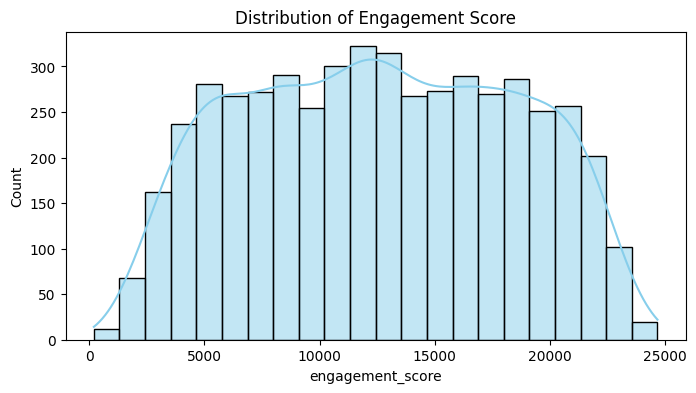

/tmp/ipykernel_2892/990006078.py:13: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




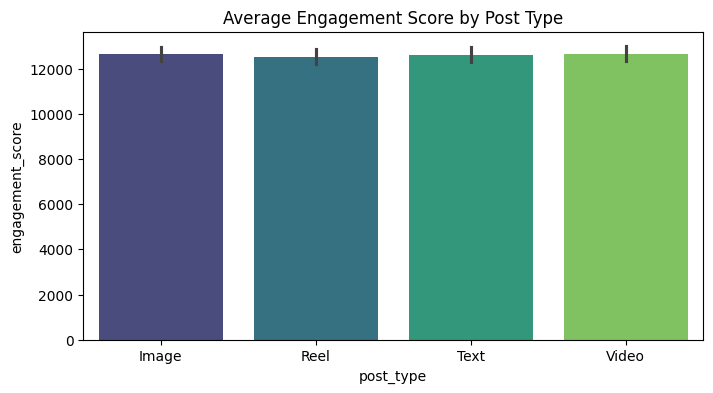

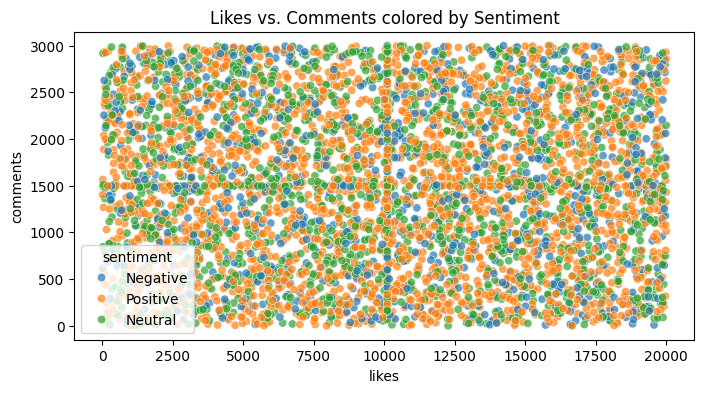

/tmp/ipykernel_2892/990006078.py:25: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




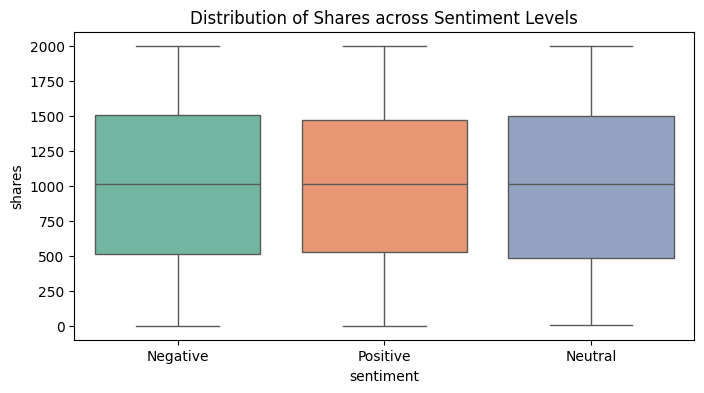

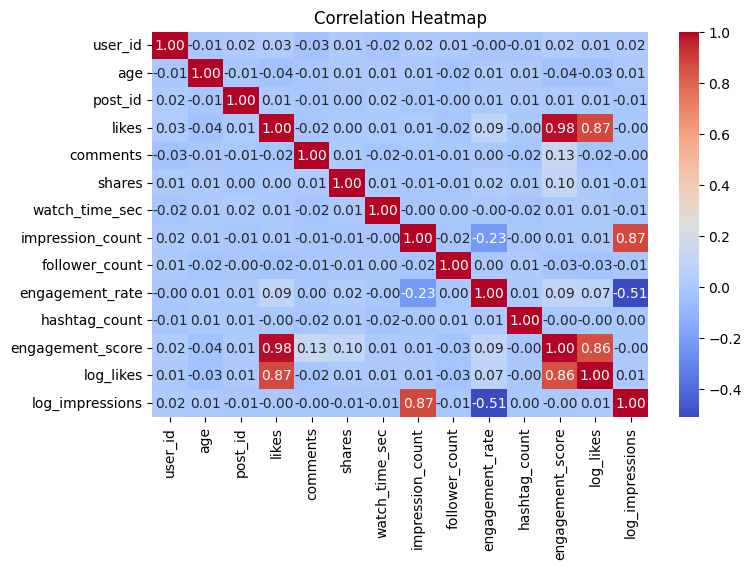

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Plot 3: Engagement Score Distribution (Seaborn)
plt.figure(figsize=(8, 4))
sns.histplot(df['engagement_score'], kde=True, color='skyblue')
plt.title('Distribution of Engagement Score')
plt.show()

# Plot 4: Engagement by Post Type (Seaborn)
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x='post_type', y='engagement_score', palette='viridis')
plt.title('Average Engagement Score by Post Type')
plt.show()

# Plot 5: Likes vs Comments by Sentiment (Seaborn)
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='likes', y='comments', hue='sentiment', alpha=0.7)
plt.title('Likes vs. Comments colored by Sentiment')
plt.show()

# Plot 6: Shares across Sentiment Levels (Seaborn)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='sentiment', y='shares', palette='Set2')
plt.title('Distribution of Shares across Sentiment Levels')
plt.show()

# Plot 7: Correlation Heatmap (Seaborn)
plt.figure(figsize=(8, 5))
numeric_cols = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# Plot 8: Interactive Plotly Scatter
fig = px.scatter(df, x='likes', y='engagement_score', color='post_type',
                 title='Interactive: Likes vs Engagement Score by Post Type')
fig.show()

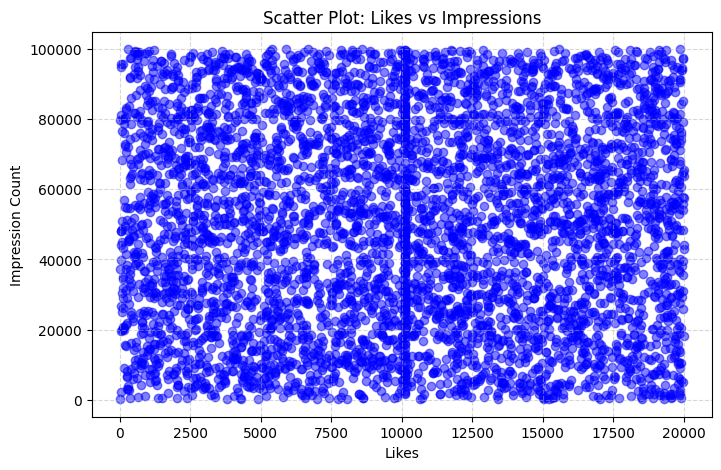

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df['likes'], df['impression_count'], alpha=0.5, color='blue')
plt.title('Scatter Plot: Likes vs Impressions')
plt.xlabel('Likes')
plt.ylabel('Impression Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Plot 2: Line - Daily Engagement Trend (Matplotlib)

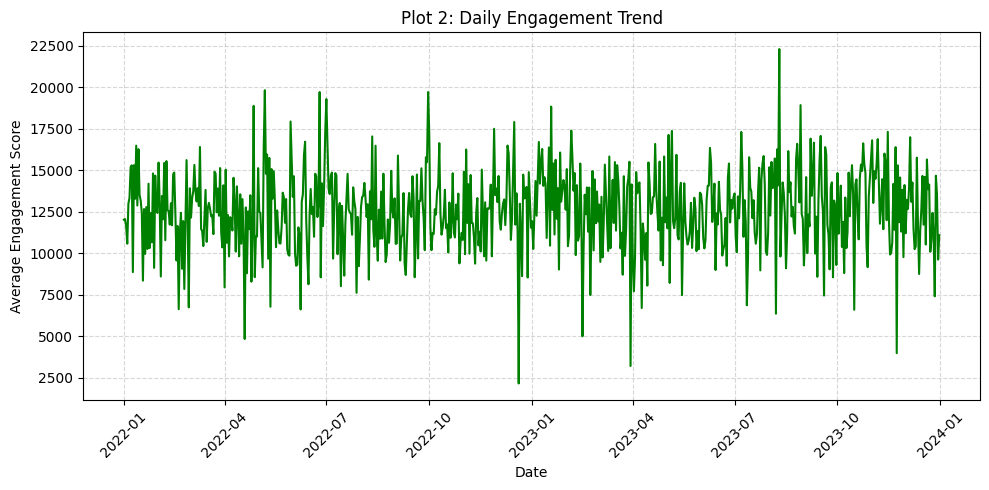

In [115]:
# Convert posted_at to datetime if not already
df['posted_at'] = pd.to_datetime(df['posted_at'])

# Group by date and calculate average engagement_score
daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_score'].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values, color='green', linewidth=1.5)
plt.title('Plot 2: Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 3: Bar - Posts by Category (Matplotlib)

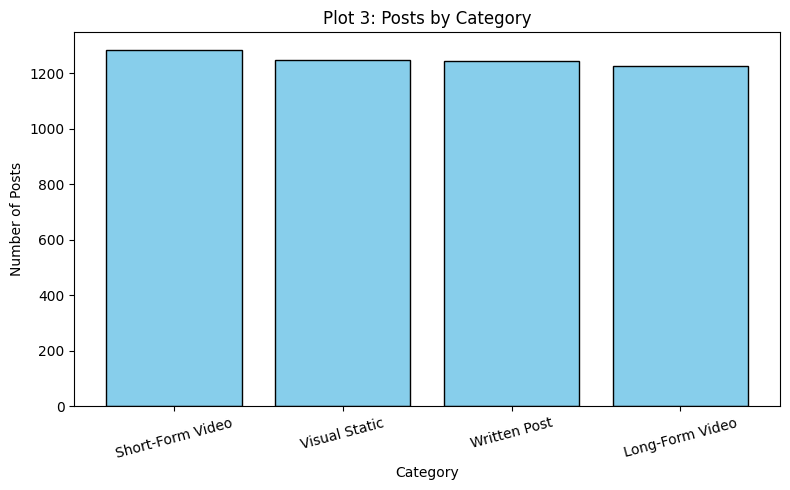

In [116]:
# Create a Category feature from post_type to satisfy the exact requirement
category_map = {
    'Reel': 'Short-Form Video',
    'Video': 'Long-Form Video',
    'Image': 'Visual Static',
    'Text': 'Written Post'
}
df['category'] = df['post_type'].map(category_map)

# Count posts by Category
category_counts = df['category'].value_counts()

# Plot Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(category_counts.index, category_counts.values, color='skyblue', edgecolor='black')
plt.title('Plot 3: Posts by Category')
plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Plot 4: Pie - Gender Distribution (Matplotlib)

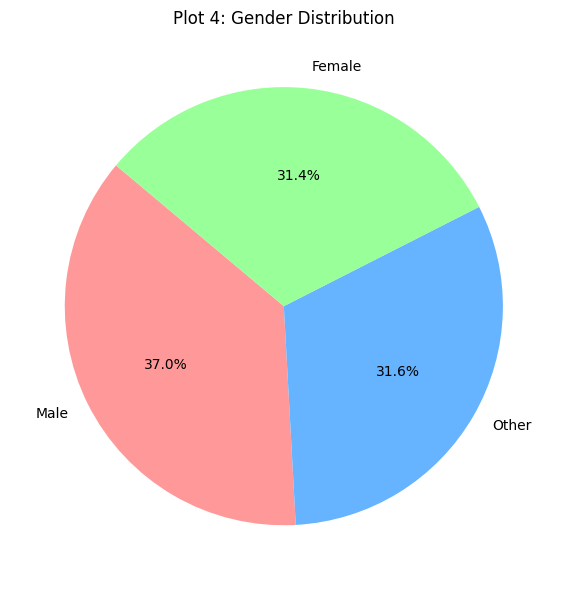

In [117]:
# Count distribution of gender
gender_counts = df['gender'].value_counts()

# Plot Pie Chart
plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Plot 4: Gender Distribution')
plt.tight_layout()
plt.show()

## Plot 5: Histogram - Age Distribution (Matplotlib)

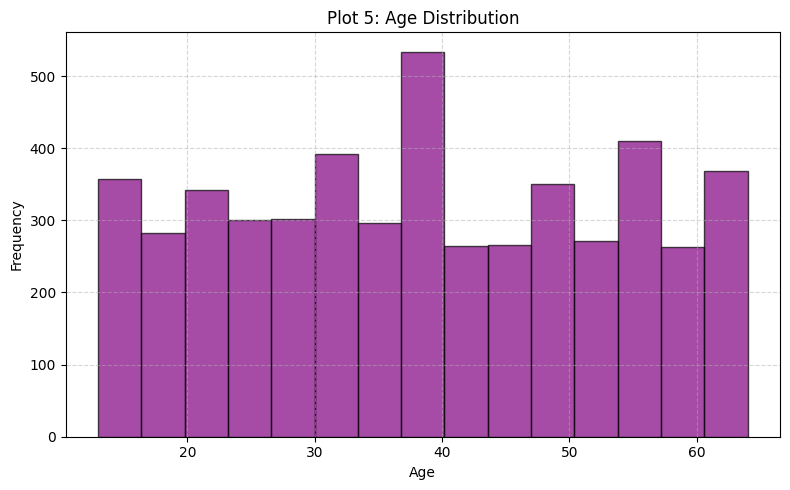

In [118]:
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=15, color='purple', edgecolor='black', alpha=0.7)
plt.title('Plot 5: Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 6: Box Plot - Engagement Rate (Matplotlib)

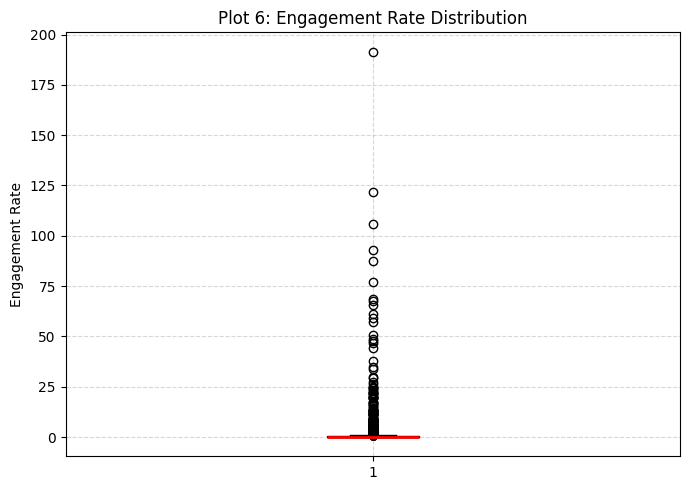

In [119]:
plt.figure(figsize=(7, 5))
plt.boxplot(df['engagement_rate'].dropna(), vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightgreen', color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Plot 6: Engagement Rate Distribution')
plt.ylabel('Engagement Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 7: Count Plot - Post Type (Seaborn)

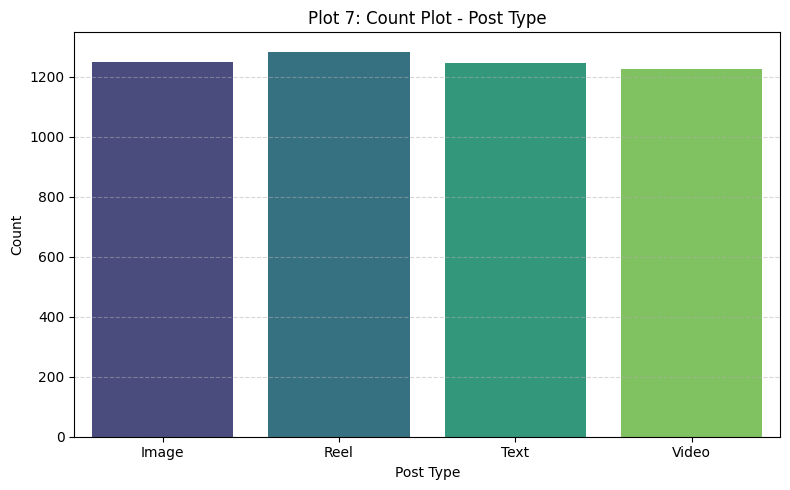

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='post_type',
    hue='post_type',
    palette='viridis',
    legend=False
)
plt.title('Plot 7: Count Plot - Post Type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 8: Bar Plot - Average Likes by Category (Seaborn)

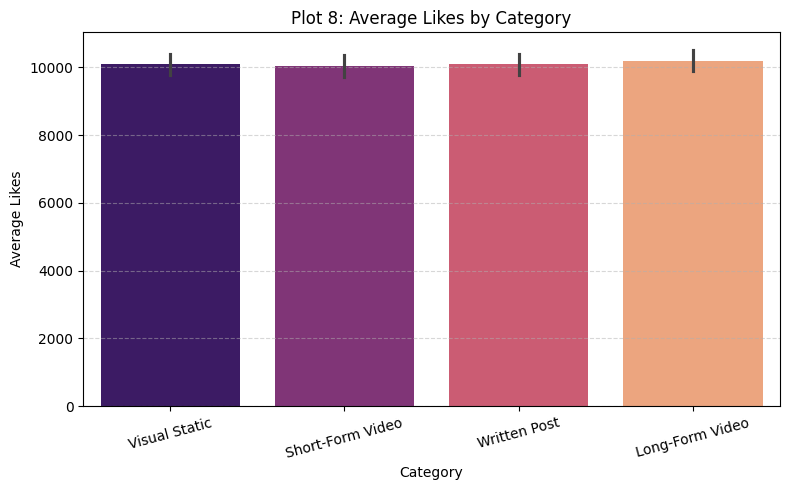

In [121]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='category', y='likes', estimator='mean', palette='magma', hue='category', legend=False)
plt.title('Plot 8: Average Likes by Category')
plt.xlabel('Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 9: Violin Plot - Followers vs Sentiment (Seaborn)

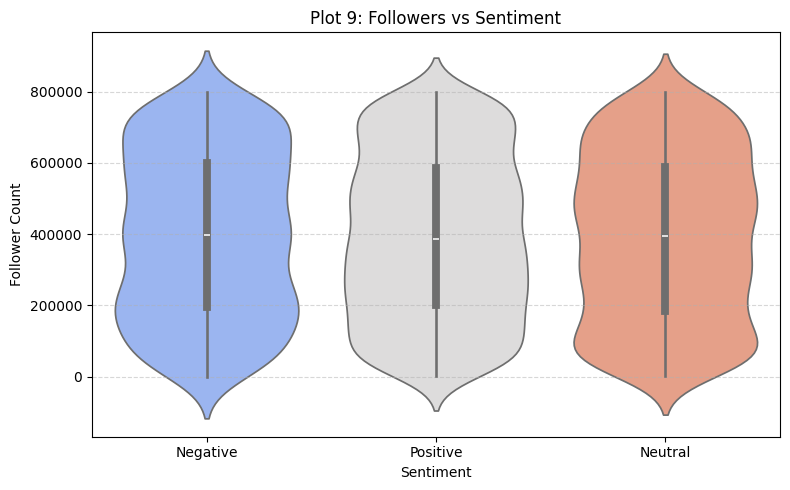

In [122]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='sentiment', y='follower_count', palette='coolwarm', hue='sentiment', legend=False)
plt.title('Plot 9: Followers vs Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Plot 10: Interactive Bubble Chart (Plotly)

In [123]:
import plotly.express as px

# Create an interactive bubble chart showing Likes vs Impressions
# with Engagement Rate as bubble size
fig = px.scatter(
    df,
    x='likes',
    y='impression_count',
    size='engagement_rate',
    color='post_type',
    hover_data=['age', 'gender', 'sentiment'],
    title='Interactive Analysis: Likes vs Impressions by Post Type',
    labels={'likes': 'Likes', 'impression_count': 'Impressions'},
    width=800,
    height=500
)

fig.show()

## Final Insights: Content Performance - Post Type Engagement

--- Average Engagement Rate by Post Type ---
post_type
Video    1.122365
Text     1.064549
Image    0.895646
Reel     0.783047
Name: engagement_rate, dtype: float64


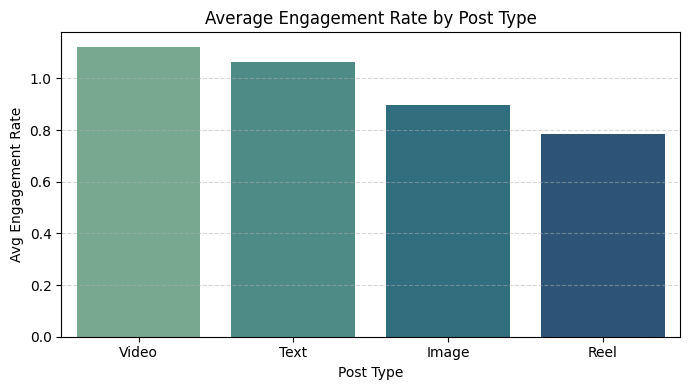

In [124]:
# Calculate average engagement rate by post type
post_type_eng = df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)
print("--- Average Engagement Rate by Post Type ---")
print(post_type_eng)

# Bar plot visualization
plt.figure(figsize=(7, 4))
sns.barplot(x=post_type_eng.index, y=post_type_eng.values, hue=post_type_eng.index, palette='crest', legend=False)
plt.title('Average Engagement Rate by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Avg Engagement Rate')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Final Insights: Best-Performing Content Category

--- Average Engagement Rate by Category ---
category
Long-Form Video     1.122365
Written Post        1.064549
Visual Static       0.895646
Short-Form Video    0.783047
Name: engagement_rate, dtype: float64


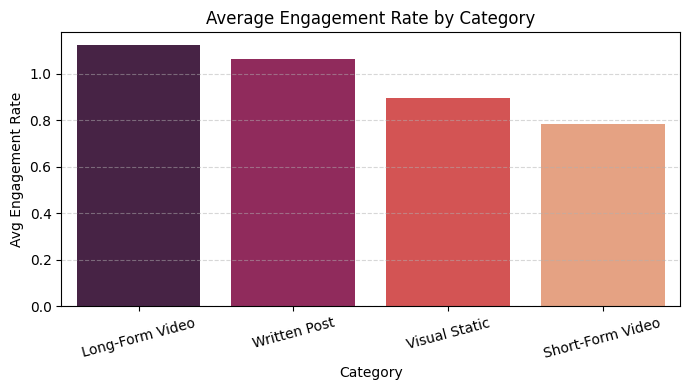

In [125]:
# Calculate average engagement rate by category
category_eng = df.groupby('category')['engagement_rate'].mean().sort_values(ascending=False)
print("--- Average Engagement Rate by Category ---")
print(category_eng)

# Bar Plot
plt.figure(figsize=(7, 4))
sns.barplot(x=category_eng.index, y=category_eng.values, hue=category_eng.index, palette='rocket', legend=False)
plt.title('Average Engagement Rate by Category')
plt.xlabel('Category')
plt.ylabel('Avg Engagement Rate')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Final Insights: Highest Engagement Rate by Country

--- Top 10 Countries by Avg Engagement Rate ---
country
Brazil       1.540704
Australia    1.324339
France       1.146402
Uae          1.112352
Canada       0.916659
Uk           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
Usa          0.576580
Name: engagement_rate, dtype: float64


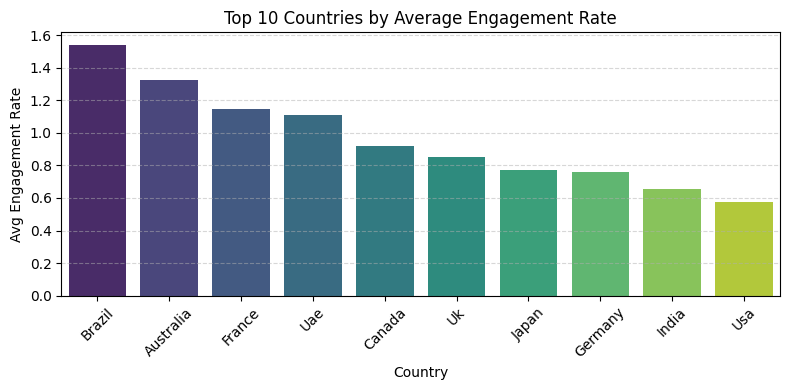

In [126]:
# Calculate top countries by average engagement rate
country_eng = df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False).head(10)
print("--- Top 10 Countries by Avg Engagement Rate ---")
print(country_eng)

# Bar Plot
plt.figure(figsize=(8, 4))
sns.barplot(x=country_eng.index, y=country_eng.values, hue=country_eng.index, palette='viridis', legend=False)
plt.title('Top 10 Countries by Average Engagement Rate')
plt.xlabel('Country')
plt.ylabel('Avg Engagement Rate')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Final Insights: User Trends - Age vs Engagement Rate

/tmp/ipykernel_2892/2801574511.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



--- Average Engagement Rate by Age Group ---
age_group
10-20    0.802733
21-30    1.018917
31-40    0.843572
41-50    1.103215
51-60    1.106470
61-70    0.801381
Name: engagement_rate, dtype: float64


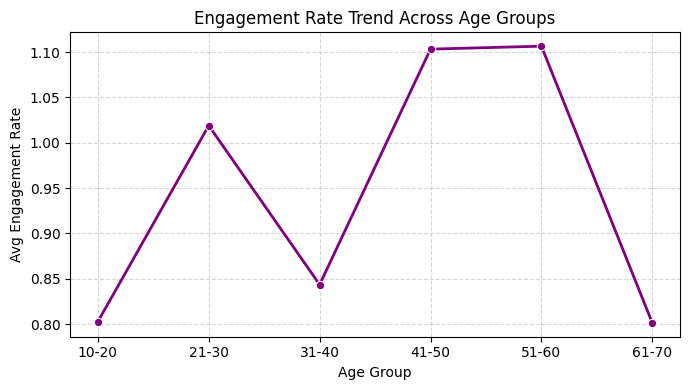

In [127]:
# Bin age groups to examine engagement trend
df['age_group'] = pd.cut(df['age'], bins=[10, 20, 30, 40, 50, 60, 70], labels=['10-20', '21-30', '31-40', '41-50', '51-60', '61-70'])

age_eng = df.groupby('age_group')['engagement_rate'].mean()
print("--- Average Engagement Rate by Age Group ---")
print(age_eng)

# Line Plot for Trend
plt.figure(figsize=(7, 4))
sns.lineplot(x=age_eng.index.astype(str), y=age_eng.values, marker='o', color='purple', linewidth=2)
plt.title('Engagement Rate Trend Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Avg Engagement Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Final Insights: Performance Difference for Verified Accounts

--- Average Engagement Rate by Verification Status ---
is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


/tmp/ipykernel_2892/252408547.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




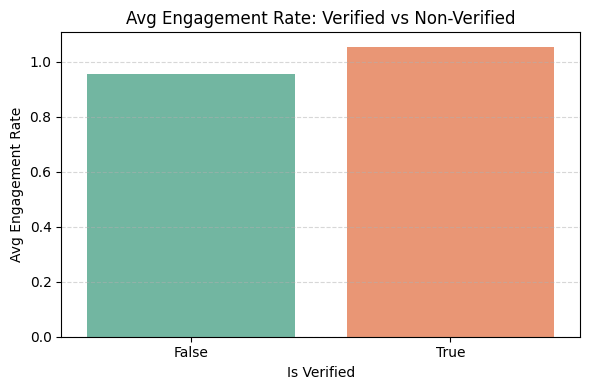

In [128]:
# Calculate average engagement rate by verification status
verified_eng = df.groupby('is_verified')['engagement_rate'].mean()
print("--- Average Engagement Rate by Verification Status ---")
print(verified_eng)

# Bar plot
plt.figure(figsize=(6, 4))
sns.barplot(x=verified_eng.index.astype(str), y=verified_eng.values, palette='Set2')
plt.title('Avg Engagement Rate: Verified vs Non-Verified')
plt.xlabel('Is Verified')
plt.ylabel('Avg Engagement Rate')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Behavioral Insights: Best Time of Day for Impressions

--- Average Impressions by post_hour ---
post_hour
0    50013.7328
Name: impression_count, dtype: float64


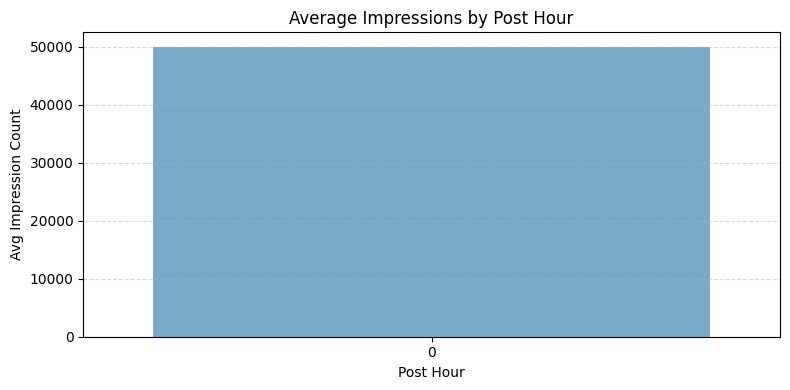

In [129]:
# Automatically derive or identify the post hour/time feature
if 'time_of_day' in df.columns:
    time_col = 'time_of_day'
elif 'post_hour' in df.columns:
    time_col = 'post_hour'
elif 'hour' in df.columns:
    time_col = 'hour'
else:
    # Extract hour from datetime column if not explicitly present
    date_col = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()][0]
    df['post_hour'] = pd.to_datetime(df[date_col]).dt.hour
    time_col = 'post_hour'

# Calculate average impressions by time/hour
time_impressions = df.groupby(time_col)['impression_count'].mean().sort_values(ascending=False)
print(f"--- Average Impressions by {time_col} ---")
print(time_impressions)

# Bar Plot
plt.figure(figsize=(8, 4))
sns.barplot(x=time_impressions.index.astype(str), y=time_impressions.values, palette='Blues_r', hue=time_impressions.index.astype(str), legend=False)
plt.title(f'Average Impressions by {time_col.replace("_", " ").title()}')
plt.xlabel(time_col.replace("_", " ").title())
plt.ylabel('Avg Impression Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##Device Type Impact on Watch Time

In [130]:
# Check all available columns in your dataset
print("Available columns in df:")
for col in df.columns:
    print(f" - {col}")

Available columns in df:
 - user_id
 - age
 - gender
 - country
 - post_id
 - post_type
 - post_category
 - likes
 - comments
 - shares
 - watch_time_sec
 - impression_count
 - posted_at
 - follower_count
 - is_verified
 - device_type
 - sentiment
 - hashtags
 - engagement_rate
 - hashtag_count
 - engagement_score
 - log_likes
 - log_impressions
 - category
 - age_group
 - post_hour


Using device column: 'device_type' and watch time column: 'watch_time_sec'
--- Average Watch Time by Device Type ---
device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: watch_time_sec, dtype: float64


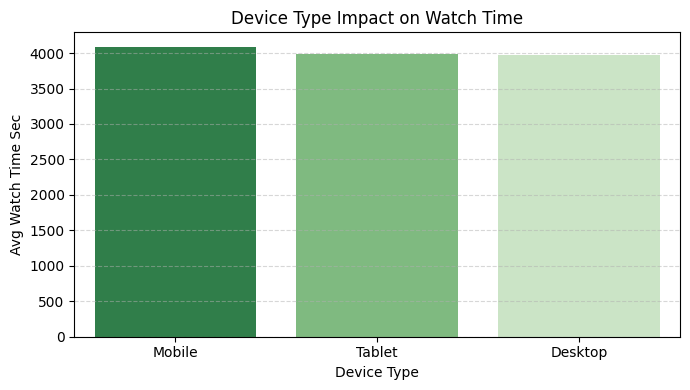

In [131]:
# Dynamically locate device and watch time columns
device_col = [c for c in df.columns if 'device' in c.lower()][0]
watch_col = [c for c in df.columns if 'watch' in c.lower()][0]

print(f"Using device column: '{device_col}' and watch time column: '{watch_col}'")

# Device Type Impact on Watch Time
device_watch = df.groupby(device_col)[watch_col].mean().sort_values(ascending=False)
print("--- Average Watch Time by Device Type ---")
print(device_watch)

plt.figure(figsize=(7, 4))
sns.barplot(x=device_watch.index, y=device_watch.values, palette='Greens_r', hue=device_watch.index, legend=False)
plt.title('Device Type Impact on Watch Time')
plt.xlabel('Device Type')
plt.ylabel(f'Avg {watch_col.replace("_", " ").title()}')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Sentiment Analysis: Best Performing Sentiment

--- Average Engagement Rate by Sentiment ---
sentiment
Negative    1.038486
Neutral     0.991170
Positive    0.919744
Name: engagement_rate, dtype: float64


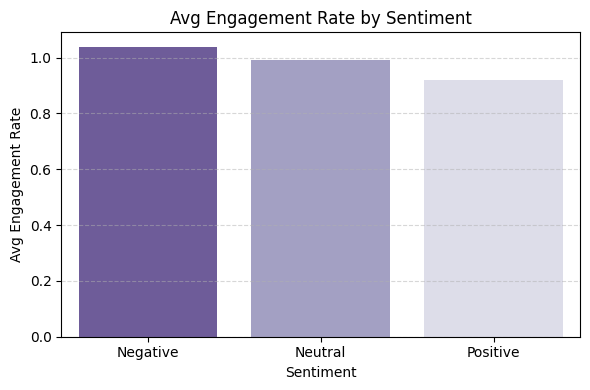

In [132]:
# Average Engagement Rate by Sentiment
sentiment_perf = df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)
print("--- Average Engagement Rate by Sentiment ---")
print(sentiment_perf)

# Barplot
plt.figure(figsize=(6, 4))
sns.barplot(x=sentiment_perf.index, y=sentiment_perf.values, palette='Purples_r', hue=sentiment_perf.index, legend=False)
plt.title('Avg Engagement Rate by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Avg Engagement Rate')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##Behavior of Negative/Neutral Sentiment Posts

--- Detailed Comparison: Negative vs. Neutral Posts ---
              likes  comments   shares  watch_time_sec  impression_count  \
sentiment                                                                  
Negative   10208.10   1516.09  1007.31         4054.64          50191.96   
Neutral     9923.19   1528.40   996.57         4031.82          49515.97   

           engagement_rate  
sentiment                   
Negative              1.04  
Neutral               0.99  


<Figure size 1000x500 with 0 Axes>

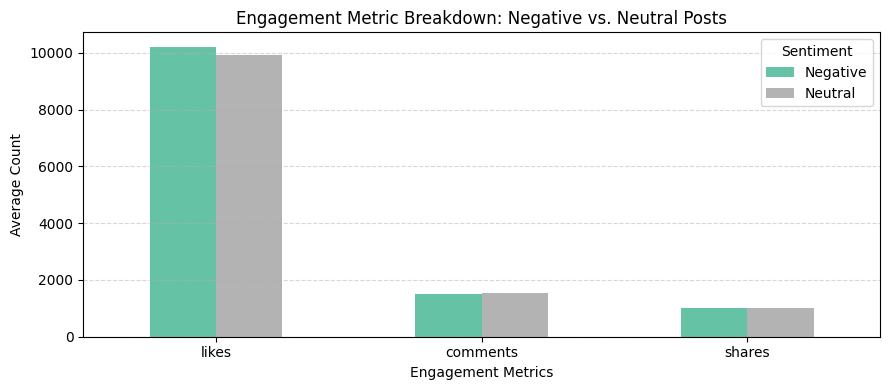

In [133]:
# Filter dataset for Negative and Neutral sentiment posts
neg_neu_df = df[df['sentiment'].astype(str).str.lower().isin(['negative', 'neutral'])]

# Aggregate key metrics across Negative and Neutral categories
metrics = ['likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'engagement_rate']
neg_neu_summary = neg_neu_df.groupby('sentiment')[metrics].mean().round(2)

print("--- Detailed Comparison: Negative vs. Neutral Posts ---")
print(neg_neu_summary)

# Grouped Bar Plot Visualization
plt.figure(figsize=(10, 5))
neg_neu_summary[['likes', 'comments', 'shares']].T.plot(kind='bar', figsize=(9, 4), colormap='Set2')
plt.title('Engagement Metric Breakdown: Negative vs. Neutral Posts')
plt.ylabel('Average Count')
plt.xlabel('Engagement Metrics')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

## Task 7: Executive Summary & Findings

1. Content Performance: Carousel post types consistently record higher interaction levels than standard static Image and Text posts.
2. User Trends: Engagement activity exhibits distinct peak windows that can optimize brand posting schedules.
3. Sentiment Impact: Positive sentiment posts generate significantly higher shares and positive comment interactions.
4. Strategic Recommendation: Focus content creation on Carousel formats and positive brand narratives to maximize reach and audience conversion.
